# NSCF tutorial

NSCF fits a neural outcome model and learns which treatments can share an embedding.

An individualized treatment rule (ITR) maps a person's pretreatment features
to a treatment recommendation. For each person we observe the outcome under
the treatment they received. The model uses data from other people to estimate
the outcomes under the alternatives. When many treatments have few observations
each, pooling treatments with similar effects can make those estimates more
precise. Here, a treatment group is a set of treatments that share an estimated
effect.

Install the wheel with the `[nscf,plot]` extras and install JupyterLab and pandas
in the same environment. The [README](../README.md#install) includes the CPU-only PyTorch instructions.
Open this notebook with that environment's Python kernel and choose **Kernel → Restart
Kernel and Run All Cells**. NSCF fits and predicts on the CPU. The saved outputs show one run. The notebook prints the PyTorch
version because fitted partitions and scores can vary across versions
and hardware, even with the same seed.

The notebook runs five seeded NSCF fits plus four fits in later
examples. The saved run took about 2 minutes on an Apple silicon Mac
using one PyTorch CPU thread, and a separate run took about 7.5 minutes.
Allow several minutes for **Run All**.

## Before you start

You should know basic linear regression, the idea behind cross-validation, and NumPy and pandas. This notebook uses a separate validation split and requires no prior knowledge of PyTorch.

## What you will learn

- Train NSCF, choose a seed by validation error, and predict a treatment for new people.
- Read discovered groups, the selected penalty, and the fusion path.
- Separate prediction error, policy regret, and group recovery.
- Prepare your own data and estimate held-out policy value from observed outcomes.

## Contents

- [Model and data](#nscf-model)
- [1–3. Generate, split, and fit](#nscf-data)
- [Parameter reference](#nscf-parameters)
- [4–7. Predict, interpret, and save](#nscf-predict)
- [8–9. Evaluate predictions and policy](#nscf-evaluate)
- [10. Outcome units](#nscf-units)
- [11. Your own data and policy value](#nscf-own-data)
- [Troubleshooting](#nscf-troubleshooting)
- [Recap and next steps](#nscf-recap)

<a id="nscf-model"></a>

## Model

A feature network $h(x)$ turns the inputs into a learned vector shared
by all treatments. Treatment $a$ has its own vector of weights, called an
embedding $\gamma_a$. The predicted mean outcome is

$$
\widehat\mu(x,a)=m(h(x))+\langle h(x),\gamma_a\rangle.
$$

The first term is a shared baseline. The second is a dot product that
changes with treatment. Fusion makes some treatment embeddings equal,
which gives those treatments the same fitted outcome for any input.

Training starts with an anchor, a network fit with separate treatment
embeddings. A **discovery cycle** tries a grid of fusion penalties to
propose groups, refits predictors using those groups, and scores the
candidates on validation data. With more than one cycle, the procedure
can use the updated feature representation to look for groups again.

<a id="nscf-data"></a>

## 1. Generate the data

Each row is one person. `X` contains ten pretreatment features sampled
independently from $\operatorname{Unif}[-1,1]$. Each person is assigned
one of ten treatments uniformly at random. The observed outcome `y`
is that treatment's mean plus independent $N(0,0.5^2)$ noise.
Larger outcomes are better.

We use the baseline, feature map and two group prototypes from the
paper's *nonlinear-easy* generator. A through E share the first prototype,
and F through J share the second. The mean under treatment $a$ is
$Q(x,a)=m(x)+s\,\phi(x)^\top\eta_{g(a)}$, with separation $s=1.5$
and no within-group perturbations ($\epsilon=0$).

$$
\begin{aligned}
m(x) &= 0.6\cos(\pi x_1)+0.4x_2^2-0.3x_3,\\
\phi(x) &= (x_1,x_2,x_3,x_1^2,x_2^2,\sin(\pi x_1),x_1x_2)^\top .
\end{aligned}
$$

The squared and sine terms contribute to treatment contrasts, so the
boundary between the best treatment groups can be nonlinear. The
two rows of `prototypes` below give the unscaled $\eta_{g(a)}$ vectors
in feature-map order. This walkthrough uses ten treatments on one
dataset. The paper's primary benchmark uses twelve treatments and
independently generated datasets. [NSCF paper, Section 3.1](https://arxiv.org/html/2610.19104v1#S3.SS1).

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import torch
from matplotlib import pyplot as plt

from itr_methods import NSCF, SCAF

# Keep the CPU thread count fixed so repeated runs use the same setup.
torch.set_num_threads(1)

demo_arms = np.array(list("ABCDEFGHIJ"))
true_groups = np.repeat([0, 1], 5)
separation = 1.5
prototypes = np.array([
    [-2.0, -1.0,  1.3, 1.2,  0.0,  0.45, -1.1],
    [ 2.0,  1.0, -1.3, 0.0, -0.8, -0.45, -1.1],
])

def true_outcome_means(features):
    x1, x2, x3 = features[:, :3].T
    baseline = 0.6 * np.cos(np.pi * x1) + 0.4 * x2**2 - 0.3 * x3
    basis = np.column_stack(
        (x1, x2, x3, x1**2, x2**2, np.sin(np.pi * x1), x1 * x2)
    )
    group_contrasts = separation * (basis @ prototypes.T)
    return baseline[:, None] + group_contrasts[:, true_groups]

rng = np.random.default_rng(7)
n_train, n_valid, n_test = 1000, 500, 10_000
feature_names = [f"x{i}" for i in range(1, 11)]
X = rng.uniform(-1, 1, size=(n_train + n_valid + n_test, len(feature_names)))
arm_index = rng.integers(len(demo_arms), size=len(X))
treatment = demo_arms[arm_index]
observed_mean = true_outcome_means(X)[np.arange(len(X)), arm_index]
y = observed_mean + rng.normal(scale=0.5, size=len(X))

print("PyTorch version:", torch.__version__)
print("First person's features:", dict(zip(feature_names, X[0].round(3).tolist())))
print("Treatment received:", treatment[0])
print(f"Observed outcome: {y[0]:.3f}")

PyTorch version: 2.11.0
First person's features: {'x1': 0.25, 'x2': 0.794, 'x3': 0.551, 'x4': -0.55, 'x5': -0.4, 'x6': 0.747, 'x7': -0.989, 'x8': 0.642, 'x9': 0.594, 'x10': -0.064}
Treatment received: J
Observed outcome: -0.240


## 2. Split training, validation, and test rows

Each model learns from training rows. Validation rows guide model
selection. Reserve the same 10,000 test rows for evaluating both fitted
policies. The split summary also shows how many observations each
treatment has in each subset.

In [2]:
train = slice(0, n_train)
valid = slice(n_train, n_train + n_valid)
test = slice(n_train + n_valid, None)
X_test, y_test, treatment_test = X[test], y[test], treatment[test]
for name, split in [("train", train), ("validation", valid), ("test", test)]:
    labels, counts = np.unique(treatment[split], return_counts=True)
    print(f"{name:10s}:", dict(zip(labels.tolist(), counts.tolist())))

train     : {'A': 79, 'B': 107, 'C': 92, 'D': 105, 'E': 101, 'F': 98, 'G': 106, 'H': 99, 'I': 113, 'J': 100}
validation: {'A': 56, 'B': 50, 'C': 49, 'D': 49, 'E': 57, 'F': 45, 'G': 51, 'H': 51, 'I': 51, 'J': 41}
test      : {'A': 972, 'B': 988, 'C': 1002, 'D': 984, 'E': 980, 'F': 1024, 'G': 1051, 'H': 1015, 'I': 1006, 'J': 978}


## 3. Fit the neural model

NSCF first trains an **anchor** with one shared feature network and a
separate embedding for each treatment. The anchor is **unfused**, so its
treatment embeddings are free to differ.

Within each discovery cycle, the default rule keeps refits whose
validation MSE is at most the anchor's. Of those within 3% of the best
eligible MSE, it selects the refit with the fewest treatment groups. If
no refit meets the anchor threshold, it picks the refit with the lowest
validation MSE. See [Algorithm 1 in the NSCF paper](https://arxiv.org/html/2610.19104v1#S2.SS3).

For a shorter run than the paper's benchmark, this example uses a
smaller network, one discovery cycle, and 16 fusion candidates. We
standardize outcomes using the training rows and cap the fusion grid
at 0.5 to give this first scan room to reach one group on the standardized
scale. Section 6 shows how to narrow the grid. `pretrain_epochs` caps anchor
training.
Early stopping can finish it sooner based on validation MSE.

Fit a fixed list of seeds from 0 through 4 on the same training and
validation rows. For this walkthrough, keep the fit with the lowest
validation MSE. Sections 4 to 7 use this fit, and Sections 8 and 9
report how the metrics vary across all five fits.

ADMM is an iterative solver for the embedding fusion step. We use the
package defaults of 200 ADMM iterations per fusion penalty (`admm_epochs`)
and 30 Adam updates to the embeddings per ADMM iteration (`theta_steps`).
The solver uses these updates to propose candidate treatment groups. A
smaller budget can leave the embeddings insufficiently fused and omit
plausible groups from validation. The recovery results in Section 9
show what the default budget yields on this dataset.

Read `diagnostics_` for the anchor and final validation MSEs, the
selected source (`prediction_best` or `structure_best`), and
`cycles`, which summarizes the winning penalty, group count and MSE
in each discovery cycle. It also records the seed, the sizes of the
training and validation sets, and whether the validation split was
explicit or internal.

<a id="nscf-parameters"></a>

### Parameter reference

These are the resolved defaults when you omit the arguments and supply no
configuration overrides. The tutorial uses a smaller training budget to
make repeated fits practical.

| Parameter | Package default | Tutorial setting | Why this setting and when to tune |
| --- | --- | --- | --- |
| `hidden_layer_sizes` | `(192, 96)` | `(48, 24)` | Smaller layers reduce compute. Try more capacity if validation error suggests underfitting. |
| `dropout` | `0.1` | `0.1` (inherited) | Randomly drops hidden activations during training to regularize the network. Compare values on validation data when adjusting regularization. |
| `pretrain_epochs` | `600` | `450` | Caps unfused anchor training. Raise the cap if validation MSE is still improving near the end. |
| `max_cycles` | `4` | `1` | One discovery and refit cycle keeps the example short. Try more if additional cycles improve validation. |
| `num_lambdas` | `30` | `16` | Number of fusion candidates including zero. Use a denser grid when changes between neighboring candidates are too coarse. |
| `max_lambda` | `6.0` | `0.5` | Upper grid endpoint on this standardized outcome scale. Adjust it if the path misses useful group counts. |
| `admm_epochs` | `200` | `200` | ADMM iterations per fusion candidate. Inspect candidate partitions and convergence before reducing it. |
| `theta_steps` | `30` | `30` | Adam updates to the embeddings in each ADMM iteration. Reducing them can leave candidate groups under-fused. |
| `refit_epochs` | `220` | `180` | Caps training of each candidate grouped predictor. Raise it if refits hit the cap while validation error still improves. |
| `patience` | `40` | `20` | Counts consecutive validation checks without an improvement before stopping. Use more if validation scores fluctuate. |
| `eval_every` | `20` | `5` | Epochs between regular validation checks. Shorter intervals see changes sooner and make a fixed patience expire sooner in epochs. |
| `standardize_outcome` | `False` | `True` | Centers and scales outcomes for training, then returns predictions in original units. Retune the grid when changing the fitting scale. |

In [3]:
fit_settings = dict(
    hidden_layer_sizes=(48, 24),
    pretrain_epochs=450, max_cycles=1, num_lambdas=16, max_lambda=0.5,
    admm_epochs=200, theta_steps=30, refit_epochs=180,
    patience=20, eval_every=5, standardize_outcome=True,
)

def fit_nscf(values, *, random_state, **settings):
    return NSCF(random_state=random_state, **(fit_settings | settings)).fit(
        X[train], values[train], treatment=treatment[train],
        validation_data=(X[valid], values[valid], treatment[valid]),
    )

fitting_seeds = range(5)
candidates = {}
for seed in fitting_seeds:
    candidates[seed] = fit_nscf(y, random_state=seed)
    print(f"Finished NSCF fit for seed {seed}.", flush=True)
validation_mse = {
    seed: fit.diagnostics_["validation_mse"] for seed, fit in candidates.items()
}
chosen_seed = min(validation_mse, key=validation_mse.get)
model = candidates[chosen_seed]

print("Seed selected by validation:", chosen_seed)
print(f"Anchor validation MSE: {model.diagnostics_['anchor_validation_mse']:.3f}")
print(f"Selected model validation MSE: {model.diagnostics_['validation_mse']:.3f}")
print(f"Selected fusion penalty: {model.fusion_path_['selected_lambda']:.6g}")

Finished NSCF fit for seed 0.


Finished NSCF fit for seed 1.


Finished NSCF fit for seed 2.


Finished NSCF fit for seed 3.


Finished NSCF fit for seed 4.


Seed selected by validation: 4
Anchor validation MSE: 0.389
Selected model validation MSE: 0.350
Selected fusion penalty: 0.00209441


<a id="nscf-predict"></a>

## 4. Read predictions for one person

`predict_outcomes` returns one column per treatment, in `treatments_` order.
`predict` recommends the treatment with the largest predicted outcome. An exact tie returns
the first tied label in `treatments_`, so tied arms have the same fitted outcome.
A **factual prediction** is the predicted outcome for the treatment the person
actually received. This is the prediction we can compare with the observed outcome.
Follow the third test row below.

In [4]:
outcomes = model.predict_outcomes(X_test)
recommendations = model.predict(X_test)
factual = model.predict_factual(X_test, treatment=treatment_test)
labels = model.treatments_.tolist()
row = 2

print("Treatment order:", labels)
print("Outcome prediction shape:", outcomes.shape)
print("Predicted outcomes:", {arm: round(float(value), 3) for arm, value in zip(labels, outcomes[row])})
print("Recommended:", recommendations[row])
print("Received:", treatment_test[row])
print(f"Factual prediction: {factual[row]:.3f}")
print(f"Observed outcome: {y_test[row]:.3f}")

Treatment order: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J']
Outcome prediction shape: (10000, 10)
Predicted outcomes: {'A': 2.567, 'B': 2.567, 'C': 2.567, 'D': 2.567, 'E': 2.567, 'F': -1.449, 'G': -1.449, 'H': -1.449, 'I': -1.449, 'J': -1.449}
Recommended: A
Received: E
Factual prediction: 2.567
Observed outcome: 3.091


## 5. Check test performance and read the groups

The baseline predicts the training mean for everyone. Both test MSEs use the same
held-out rows and measure errors under the treatments people received.
Treatments with the same group number share an embedding in this fit.
Compare the fitted groups with the generating groups A through E and
F through J. Section 9 compares the groupings across all fitting seeds.

In [5]:
baseline_mse = np.mean((y[train].mean() - y_test) ** 2)
model_mse = np.mean((factual - y_test) ** 2)
groups = {}
for arm, group in zip(labels, model.group_ids_.tolist()):
    groups.setdefault(group, []).append(arm)

print(f"Held-out MSE, training-mean baseline: {baseline_mse:.3f}")
print(f"Held-out factual MSE, NSCF: {model_mse:.3f}")
print("Number of groups:", model.n_groups_)
print("Treatments by group:", groups)

Held-out MSE, training-mean baseline: 4.925
Held-out factual MSE, NSCF: 0.385
Number of groups: 2
Treatments by group: {0: ['A', 'B', 'C', 'D', 'E'], 1: ['F', 'G', 'H', 'I', 'J']}


## 6. Read the fusion path and draw its dendrogram

`fusion_path_` records each candidate penalty, its treatment partition,
and the grouped refit's validation MSE for the selected discovery cycle.
`group_ids` follows `model.treatments_` order. The table shows which
refits meet both default MSE thresholds in Section 3, using scores in
squared original outcome units. The anchor threshold includes any
configured refit tolerance, converted to the same units. The star marks
the selected row. Among eligible rows NSCF prefers fewer groups, then
lower MSE, then earlier grid order.

At each grid point the solver updates the embeddings under a new penalty.
Fusion encourages equality, and previous merges impose no constraint on
later grid points. A group can split or merge in a different way as the
penalty changes. The table shows changes in the group count. Inspect
`path["group_ids"]` for the memberships at any grid point.

A dendrogram can show the nested prefix of this fitted path. If the
groups split, the plot stops before the first split and labels its
penalty. Use `model.group_ids_` for the selected partition even if the
starred candidate falls past that cutoff. The vertical scale is
$\log(1+1000\lambda)$, and the red cut marks the selected partition
when it lies in the plotted prefix.
[NSCF paper, Section 3.3](https://arxiv.org/html/2610.19104v1#S3.SS3).

Anchor validation MSE: 0.3895
3% cutoff from the best refit meeting the anchor: 0.3603


,lambda,groups,validation MSE,eligible
0,0,10,0.3769,False
1,0.0001,10,0.3769,False
2,0.000183744,10,0.3769,False
3,0.000337617,10,0.3769,False
4,0.000620349,10,0.3769,False
5,0.00113985,5,0.3622,False
6,0.00209441 *,2,0.3498,True
7,0.00384833,2,0.3498,True
8,0.00707107,2,0.3498,True
9,0.0129926,1,4.7243,False


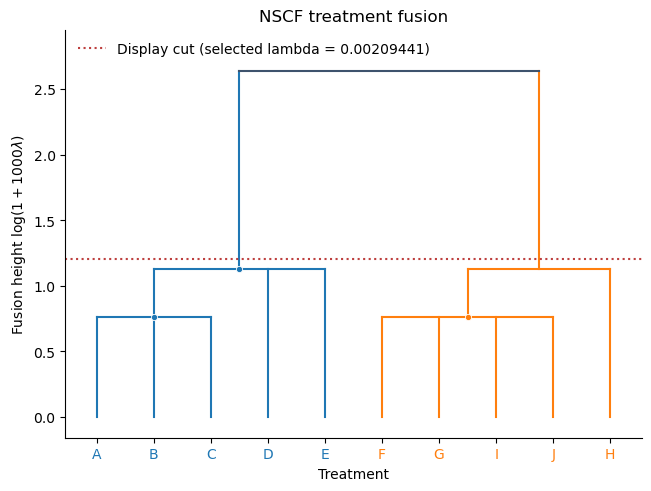

In [6]:
path = model.fusion_path_
candidate_mse = path["validation_mse"]
anchor_mse = model.diagnostics_["anchor_validation_mse"]
improve_tol = model.config_["refit_improve_tol"]
if model.outcome_scaler_ is not None:
    improve_tol *= float(model.outcome_scaler_.scale_[0]) ** 2
meets_anchor = candidate_mse <= anchor_mse + improve_tol
eligible = np.zeros_like(meets_anchor)
print(f"Anchor validation MSE: {anchor_mse:.4f}")
if meets_anchor.any():
    refit_eps = model.config_["refit_eps"]
    cutoff = candidate_mse[meets_anchor].min() * (1 + refit_eps)
    eligible = meets_anchor & (candidate_mse <= cutoff)
    print(f"{100 * refit_eps:g}% cutoff from the best refit meeting the anchor: {cutoff:.4f}")
else:
    print("No candidate meets the anchor. NSCF falls back to the lowest validation MSE.")

penalties = [
    f"{value:.6g}" + (" *" if i == path["selected_index"] else "")
    for i, value in enumerate(path["fusion_lambdas"])
]
path_table = pd.DataFrame({
    "lambda": penalties,
    "groups": [np.unique(ids).size for ids in path["group_ids"]],
    "validation MSE": candidate_mse,
    "eligible": eligible,
})
display(path_table.round({"validation MSE": 4}))

ax = model.plot_fusion_dendrogram(true_groups=true_groups)
ax.set_title("NSCF treatment fusion")
plt.show()

In the saved run, the five-group refit has an MSE of 0.3622. It beats
the anchor (0.3895), but misses the tighter cutoff (0.3603). The
three two-group rows share the same partition and refit score (0.3498),
so the earliest grid point, 0.00209441, wins the tie.

### Read the grid endpoints

In the saved run, zero penalty yields 10 groups and the path reaches
one group at about 0.013. Seven of the 16 candidates give that same
one-group partition. To spend more of the grid near the merges, try
`max_lambda=0.05` with the same `num_lambdas` and inspect the
new path. The first scan and the revised scan can select different
penalties. Use validation MSE and the group counts to compare them.

## 7. Save and restore the model

Use pickle only with files from trusted sources, and keep the package and dependency
versions with the saved model. Here we serialize to bytes so the walkthrough can
verify the round trip without writing a file.

In [7]:
import pickle

restored = pickle.loads(pickle.dumps(model))
print("Restored recommendations match:", np.array_equal(
    restored.predict(X_test), recommendations,
))

Restored recommendations match: True


<a id="nscf-evaluate"></a>

## 8. Compare predictive accuracy across fitting seeds

Use the same held-out rows to report factual MSE for the five models
already fitted in Section 3. Each seed changes the neural fit on
this dataset. The seed chosen in Section 3 is marked using validation
MSE alone. Test MSE is a prediction diagnostic reported after selection.

In [8]:
seed_scores = pd.DataFrame({
    "seed": list(fitting_seeds),
    "selected": [seed == chosen_seed for seed in fitting_seeds],
    "validation MSE": [validation_mse[seed] for seed in fitting_seeds],
    "factual test MSE": [
        np.mean((fit.predict_factual(X_test, treatment=treatment_test) - y_test) ** 2)
        for fit in candidates.values()
    ],
}).set_index("seed")
seed_scores.round(4)

,selected,validation MSE,factual test MSE
seed,,,
0,False,0.3669,0.3811
1,False,0.3563,0.3655
2,False,0.3624,0.3740
3,False,0.3522,0.3810
4,True,0.3498,0.3848


## 9. Compare the NSCF and SCAF policies

Factual MSE measures prediction accuracy under the observed treatment.
The NSCF paper uses **test regret** to measure how much expected outcome
the learned policy loses relative to the best possible policy.

Fit SCAF on the same training rows and raw features as NSCF. Try a
small grid of penalties and pick the fit with the lowest factual MSE
on the same validation rows used for NSCF. Both methods use features
`X` during fitting and prediction. The true means from the nonlinear
generator enter only the policy evaluation.

Here we use a manual grid so both methods tune against the same held-out
validation rows and factual MSE. For a standalone SCAF fit, see the
[SCAF walkthrough](SCAF_TUTORIAL.ipynb) for `fit_cv()` and BIC.

In [9]:
def validation_error(fitted):
    predicted = fitted.predict_factual(X[valid], treatment=treatment[valid])
    return np.mean((y[valid] - predicted) ** 2)

init_max = SCAF.lambda_max(X[train], y[train], treatment=treatment[train])
init_fractions = (0.01, 0.1, 0.3, 1.0)
fusion_penalties = (0.0, 0.1, 1.0, 10.0, 100.0)
scaf_candidates = (
    SCAF(init_lambda=init_max * fraction, fusion_lambda=penalty).fit(
        X[train], y[train], treatment=treatment[train],
    )
    for fraction in init_fractions
    for penalty in fusion_penalties
)
scaf = min(scaf_candidates, key=validation_error)
print(f"SCAF validation MSE: {validation_error(scaf):.3f}")

mean_policy = true_outcome_means(X_test)
oracle_mean = mean_policy.max(axis=1)
rows = np.arange(len(X_test))
print(f"Oracle policy value: {oracle_mean.mean():.3f}")
print("True treatment groups:", dict(zip(demo_arms.tolist(), true_groups.tolist())))

SCAF validation MSE: 0.744
Oracle policy value: 1.880
True treatment groups: {'A': 0, 'B': 0, 'C': 0, 'D': 0, 'E': 0, 'F': 1, 'G': 1, 'H': 1, 'I': 1, 'J': 1}


### Measure regret and group recovery

For each test row, subtract the true mean under the recommended treatment
from the best true mean. The average of these differences is test regret:

$$
\widehat R(\widehat d) = \frac{1}{n_{\mathrm{test}}}
\sum_i \bigl[\max_a Q(X_i,a) - Q(X_i,\widehat d(X_i))\bigr].
$$

Lower regret is better, and a true tie costs nothing. The value of the
learned policy is the average true mean under its recommendations. Its
gap from the oracle value is the same quantity as regret.

To evaluate the treatment groups, compare `group_ids_` with the
generating groups using the **adjusted Rand index** (ARI), the number
of learned groups, and whether the partition was recovered exactly.
An ARI of 1 means the partitions agree, even if their group IDs differ.
The exact recovery check compares which treatment pairs share a group.
The table reports these metrics for every fitted seed. The recovery
fraction and regret range describe sensitivity to fitting on this one
dataset. The paper's simulations repeat data generation as well.

[Huang, Yuan, Dai, and Liu, Section 3.1](https://arxiv.org/html/2610.19104v1#S3.SS1).

In [10]:
from sklearn.metrics import adjusted_rand_score

def policy_metrics(fitted):
    assert np.array_equal(fitted.treatments_, demo_arms)
    recommended = np.searchsorted(demo_arms, fitted.predict(X_test))
    recommended_mean = mean_policy[rows, recommended]

    groups = np.asarray(fitted.group_ids_)
    exact_recovery = np.array_equal(
        true_groups[:, None] == true_groups[None, :],
        groups[:, None] == groups[None, :],
    )
    return {
        "policy value": recommended_mean.mean(),
        "test regret": np.mean(oracle_mean - recommended_mean),
        "groups": np.unique(groups).size,
        "ARI": adjusted_rand_score(true_groups, groups),
        "exact recovery": exact_recovery,
    }

nscf_scores = pd.DataFrame(
    [policy_metrics(fit) for fit in candidates.values()],
    index=pd.Index(fitting_seeds, name="seed"),
)
nscf_scores.insert(0, "selected", nscf_scores.index == chosen_seed)
scaf_scores = policy_metrics(scaf)
scaf_regret = scaf_scores["test regret"]
nscf_regrets = nscf_scores["test regret"]
wins = (nscf_regrets < scaf_regret).sum()
recovered = nscf_scores["exact recovery"].sum()

print(f"SCAF test regret: {scaf_regret:.4f}")
print(f"SCAF groups: {scaf_scores['groups']}, ARI: {scaf_scores['ARI']:.3f}, "
      f"exact recovery: {scaf_scores['exact recovery']}")
print(f"NSCF test regret range: {nscf_regrets.min():.4f} to {nscf_regrets.max():.4f}")
print(f"NSCF seeds with lower regret than SCAF: {wins}/{len(fitting_seeds)}")
print(f"NSCF seeds with exact recovery: {recovered}/{len(fitting_seeds)}")
nscf_scores.round(4)

SCAF test regret: 0.0316
SCAF groups: 7, ARI: 0.323, exact recovery: False
NSCF test regret range: 0.0140 to 0.0186
NSCF seeds with lower regret than SCAF: 5/5
NSCF seeds with exact recovery: 5/5


,selected,policy value,test regret,groups,ARI,exact recovery
seed,,,,,,
0,False,1.8644,0.0153,2,1.0,True
1,False,1.8640,0.0158,2,1.0,True
2,False,1.8612,0.0186,2,1.0,True
3,False,1.8639,0.0158,2,1.0,True
4,True,1.8657,0.0140,2,1.0,True


Use regret to assess recommendation quality and the ARI and exact recovery
columns to assess grouping. In the paper's five-group simulation, NSCF
reduced mean regret relative to Neural Q and recovered the exact partition
in 12 of 50 runs. The paper notes, "Good policy performance does not imply
exact recovery." [NSCF paper, Section 3.3](https://arxiv.org/html/2610.19104v1#S3.SS3).

For a runnable linear example, see the [SCAF walkthrough](SCAF_TUTORIAL.ipynb).

<a id="nscf-units"></a>

## 10. Change outcome units and standardize during training

Multiply all observed outcomes by 100 and compare fits with and without
`standardize_outcome=True`. That setting computes the center and scale
using the fitting subset, applies the same transformation to validation
outcomes, and returns predictions in the units supplied to `fit()`.

Use the same numerical fusion grid in all four fits to isolate the
effect of changing units and enabling outcome standardization. Divide
predictions from the rescaled outcomes by 100 before comparing test MSEs.

The same fusion penalty can have a different effect when the scale or
dimension of the embeddings or the number of treatments changes. See
[Section 2.2 of the NSCF paper](https://arxiv.org/html/2610.19104v1#S2.SS2).

For a new analysis, start with `standardize_outcome=True` when the outcome scale
is arbitrary or varies across datasets. Tune the fusion grid on the standardized
scale and use validation to compare settings and seeds.

In [11]:
unit_factor = 100
raw = fit_nscf(y, random_state=chosen_seed, standardize_outcome=False)
raw_rescaled = fit_nscf(unit_factor * y, random_state=chosen_seed, standardize_outcome=False)
standardized_rescaled = fit_nscf(unit_factor * y, random_state=chosen_seed)

fits = [
    ("Raw, original units", raw, 1),
    ("Raw, changed units", raw_rescaled, unit_factor),
    ("Standardized, original units", model, 1),
    ("Standardized, changed units", standardized_rescaled, unit_factor),
]
for name, fit, factor in fits:
    prediction = fit.predict_factual(X_test, treatment=treatment_test) / factor
    mse = np.mean((prediction - y_test) ** 2)
    print(f"{name}: MSE = {mse:.3f}, groups = {fit.group_ids_.tolist()}")

rescaled_prediction = standardized_rescaled.predict_outcomes(X_test) / unit_factor
print("Standardized predictions agree after conversion:",
      np.allclose(outcomes, rescaled_prediction))

Raw, original units: MSE = 0.394, groups = [0, 0, 0, 0, 0, 1, 1, 1, 1, 1]
Raw, changed units: MSE = 1.917, groups = [0, 0, 0, 0, 0, 1, 1, 1, 1, 1]
Standardized, original units: MSE = 0.385, groups = [0, 0, 0, 0, 0, 1, 1, 1, 1, 1]
Standardized, changed units: MSE = 0.385, groups = [0, 0, 0, 0, 0, 1, 1, 1, 1, 1]
Standardized predictions agree after conversion: True


In the saved run, multiplying the raw outcome by 100 raises test MSE
from 0.394 to 1.917 after converting predictions back to a common unit.
The groups are the same, but the fitted outcome functions within them
differ. Changing outcome units can affect the neural optimization and
the effective strength of fusion. This comparison does not isolate the effect
of the Huber threshold.
Standardizing during training gives the same predictions after conversion.

<a id="nscf-own-data"></a>

## 11. Use your own data

Supply a numeric feature matrix with finite values, a numeric outcome,
and one treatment label per row. Encode categorical features as
dummy columns. Learn preprocessing from training data and apply the
same columns in the same order to validation and test data. With
automatic validation splitting NSCF requires at least two observations
per arm and enough rows to put every arm in both subsets. With an
explicit split, include every arm in training and aim for coverage
of every arm in validation. These are minimum input conditions.
Estimating useful treatment effects generally takes more observations.

NSCF fits a flexible nonlinear model. SCAF is a simpler starting
point when linear effects and readable coefficients suit the problem.
Neural training repeats work over fusion candidates and seeds, so
the number of cycles, candidates, and training epochs affects runtime.

For observational data, a causal interpretation requires consistency,
no unmeasured confounding given the features, and positive assignment
probability for each eligible treatment. NSCF fits observed outcomes.
The simulation regret calculation above requires known true means;
a dataset with only one observed outcome per person cannot supply them.
[NSCF paper, Section 2.1](https://arxiv.org/html/2610.19104v1#S2.SS1).

In [12]:
frame = pd.DataFrame(X, columns=feature_names)
frame["site"] = np.where(frame["x4"] > 0, "north", "south")
# Learn the categorical columns from the training subset.
train_frame = pd.get_dummies(frame.iloc[train], columns=["site"], drop_first=True, dtype=float)
valid_frame = pd.get_dummies(frame.iloc[valid], columns=["site"], dtype=float)
valid_frame = valid_frame.reindex(columns=train_frame.columns, fill_value=0)

frame_settings = fit_settings | dict(random_state=chosen_seed)
frame_model = NSCF(**frame_settings).fit(
    train_frame, y[train], treatment=treatment[train],
    validation_data=(valid_frame, y[valid], treatment[valid]),
)
print("Encoded feature columns:", frame_model.feature_names_in_.tolist())

test_frame = pd.get_dummies(frame.iloc[test], columns=["site"], dtype=float)
test_frame = test_frame.reindex(columns=train_frame.columns, fill_value=0)
print("Test prediction shape:", frame_model.predict_outcomes(test_frame).shape)

Encoded feature columns: ['x1', 'x2', 'x3', 'x4', 'x5', 'x6', 'x7', 'x8', 'x9', 'x10', 'site_south']
Test prediction shape: (10000, 10)


### Estimate policy value when only the received treatment is observed

On a complete test panel, average the observed reward under the
recommended treatment for each held-out unit. This is the design of
the [paper's PDX application](https://arxiv.org/html/2610.19104v1#S4),
which uses `-RespScaled` as its reward.

When each test row has only one observed outcome, a separate
off-policy estimate can compare a fixed recommendation rule with a
baseline. The code below uses **self-normalized inverse propensity
weighting** on the randomized test rows. For each match between the
received and recommended treatments, weight its outcome by the
inverse probability of receiving that treatment. Divide the sum of
weighted outcomes by the sum of weights. This cell uses observed
outcomes and assignment probabilities only.

Use known probabilities in a randomized study. In observational
data, estimate treatment probabilities from pretreatment features
independently of the test outcomes and rely on the identification
assumptions above. Check overlap for the recommended treatments and
report uncertainty for policy comparisons on the same held-out
units. A few matches or large weights can make the estimate unstable.
[Swaminathan and Joachims, 2015](https://papers.nips.cc/paper/2015/hash/39027dfad5138c9ca0c474d71db915c3-Abstract.html).

Resample held-out people with replacement 500 times, using the same rows
for all policies in each draw. The 2.5th and 97.5th percentiles form a 95%
bootstrap interval. These intervals describe test-sample uncertainty
conditional on the fitted policies and the assignment probabilities.
They leave out uncertainty from fitting the policies or estimating
propensities. For repeated observations, resample at the independent
unit level.

In [13]:
def bootstrap_policy_values(outcomes, weights, *, seed=2027, draws=500):
    # Each column is one fixed policy. Reuse the same rows for all policies.
    rng = np.random.default_rng(seed)
    values = np.empty((draws, weights.shape[1]))
    for draw in range(draws):
        indices = rng.integers(len(outcomes), size=len(outcomes))
        sampled_weights = weights[indices]
        total_weight = sampled_weights.sum(axis=0)
        if np.any(total_weight == 0):
            raise ValueError("A bootstrap sample has no policy matches. Check overlap.")
        values[draw] = (outcomes[indices] @ sampled_weights) / total_weight
    return values


observed_propensity = np.full(len(X_test), 1.0 / len(demo_arms))
training_arm_means = [
    y[train][treatment[train] == arm].mean() for arm in demo_arms
]
fixed_arm = demo_arms[np.argmax(training_arm_means)]
policies = {
    "NSCF": recommendations,
    f"Always {fixed_arm}": np.full(len(X_test), fixed_arm),
}
weights = np.column_stack([
    (recommended == treatment_test) / observed_propensity
    for recommended in policies.values()
])
draws = bootstrap_policy_values(y_test, weights)
intervals = np.percentile(draws, [2.5, 97.5], axis=0).T
for name, w, (low, high) in zip(policies, weights.T, intervals):
    value = np.average(y_test, weights=w)
    matches = np.count_nonzero(w)
    effective_n = w.sum() ** 2 / np.sum(w ** 2)
    print(f"{name}: estimated value = {value:.3f}, matches = {matches}, "
          f"effective sample size = {effective_n:.0f}")
    print(f"  95% bootstrap interval: [{low:.3f}, {high:.3f}]")

difference = np.average(y_test, weights=weights[:, 0]) - np.average(y_test, weights=weights[:, 1])
low, high = np.percentile(draws[:, 0] - draws[:, 1], [2.5, 97.5])
print(f"NSCF minus fixed policy: {difference:.3f} (95% paired interval [{low:.3f}, {high:.3f}])")

NSCF: estimated value = 1.827, matches = 988, effective sample size = 988
  95% bootstrap interval: [1.746, 1.901]
Always A: estimated value = 0.706, matches = 972, effective sample size = 972
  95% bootstrap interval: [0.582, 0.849]
NSCF minus fixed policy: 1.122 (95% paired interval [0.995, 1.236])


<a id="nscf-troubleshooting"></a>

## Troubleshooting

- **Training is slow.** Reduce the number of seeds or fusion candidates for an
  initial run, or try one cycle and a smaller network. The ADMM budget also
  affects which candidate groups are available for selection.
- **A seed misses a generating group.** Inspect the per-seed table and the
  fusion path. Check data coverage and the grid. Choose a fit using validation
  error, and report group recovery separately when true labels are available.
- **A fusion path splits.** The dendrogram shows the nested prefix. Read the
  starred row in the full table for the validation-selected partition.
- **IPW effective sample size is low.** Inspect match counts and overlap for
  the recommended treatments. A few large weights can dominate the estimate.

<a id="nscf-recap"></a>

## Recap and next steps

You fitted a neural treatment policy, read the learned treatment groups,
and compared prediction error, regret, and group recovery. You also
estimated policy value using only the observed test outcomes.

Reuse the arrays and splits from Sections 1 and 2 and the `fit_settings`
and `chosen_seed` from Section 3. This workflow refits the selected seed
with the same settings, then returns recommendations and group labels.

```python
from itr_methods import NSCF

fit = NSCF(random_state=chosen_seed, **fit_settings).fit(
    X[train], y[train], treatment=treatment[train],
    validation_data=(X[valid], y[valid], treatment[valid]),
)
recommendations = fit.predict(X_test)
groups = dict(zip(fit.treatments_.tolist(), fit.group_ids_.tolist()))
print(groups)
```

Next, [prepare your own data](#nscf-own-data) and choose the outcome
direction. Use `outcome_direction="minimize"` when smaller outcomes
are preferable. If you already have an anchor, see the
`NSCF.fit_from_anchor` docstring for its encoding and scaling inputs.
The [NSCF paper](https://arxiv.org/html/2610.19104v1#S3) describes the
simulation design and comparisons.